In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scienceplots 
from astropy.modeling import models, fitting








plt.style.use(['science', 'notebook', 'grid'])


# Generate a gaussian function to text the function

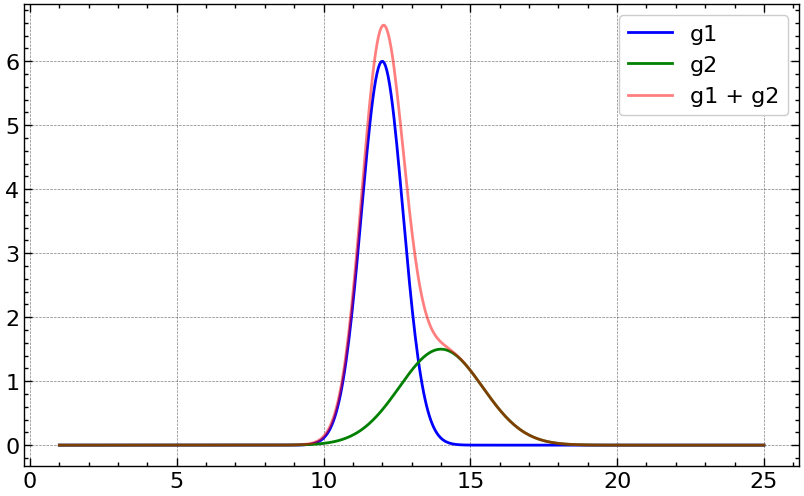

In [30]:
# gaussian function

def gaussian_function(X, amplitude, mean, stddev):
    '''
    Generate a Gaussian function.
    
    Args:
        X (array-like): Input values.
        amplitude (float): Amplitude of the Gaussian.
        mean (float): Mean of the Gaussian.
        stddev (float): Standard deviation of the Gaussian.
        
    Returns:
        array-like: Values of the Gaussian function at X.'''
    return amplitude * np.exp(-((X - mean) / (2 * stddev))**2)



# genearate X values
x = np.linspace(1, 25, 500)


# define parameters for the Gaussian
amplitude = 6
mean = 12
stddev = 1/2

# generate Gaussian values
g1 = gaussian_function(x, amplitude, mean, stddev)
g2 = gaussian_function(x, amplitude/4, mean+2, stddev*2)
y_true = g1 + g2

y_noisy = y_true + np.random.normal(0, 0.3, x.shape)


# plot the Gaussian function

plt.figure(figsize=(10, 6))
plt.plot(x, g1, label='g1', color='blue')
plt.plot(x, g2, label='g2', color='green')
plt.plot(x, y_true, label='g1 + g2', color='red', alpha=0.5)
plt.legend()

In [3]:
# Evaluate the performance of the model
def reduce_chi_square(model,frequency,power, yerr=None):

    """
    Compute reduced chi-square for a fitted astropy model.

    fit_model : astropy model (already fitted)
    frequency     : array, independent variable (frequency)
    power     : array, observed data (power)
    yerr  : array or float, optional measurement uncertainties.
            If None, use std of y as uniform error.
    """

    fit_model = model(power)
    residuals = power - fit_model

    if yerr is None:
        yerr = np.std(power) 
        
    chi2 = np.sum((residuals / yerr)**2)   
    chi2_red = chi2 / (len(frequency) - len(model.param_names))

    return chi2_red


def RMSE(power, model):
    fit_model = model(power)
    return np.sqrt(np.mean((fit_model-power)**2))

In [ ]:
# Fitting a gaussian function to the plot
# automate power epectrum inspection

# Gaussian Fitting

def gaussian_fit_RFI (frequency, power, tie):
    """ 
    The function, fittis a gaussian function to a frequency window

    Entries
    --------
    frequency: array
    power: array
    freq_min, freq_mac: frequency window
    tie: bolean - fit one or to gaussian 
        
    """

    # --- Initial Guess ---
    peak_idx = np.argmax(power)
    peak_amplitude = power[peak_idx]
    peak_frequency = frequency[peak_idx]

    # Estimate standard deviation for narrow gaussian
    delta_frequency = (frequency[1] - frequency[0])  # chanel width
    sigma_narrow = 5 * delta_frequency


    # Estimate sigma for broad band 
    median_amplitude = np.median(power)
    sigma_broad = 0.01
    amp_broad = (peak_amplitude - median_amplitude) / 5 


    # create a gaussian model for each 
    g_narrow = models.Gaussian1D(amplitude=peak_amplitude, mean=peak_frequency, stddev=sigma_narrow)
    g_broad  = models.Gaussian1D(amplitude=amp_broad, mean=peak_frequency, stddev=sigma_broad)


    if tie==True:
        # Tie the broad with the narrow
        def tie_means(model):
            return model.mean_0
        g_broad.mean.tied = tie_means

        # combine them
        model_init = g_narrow + g_broad

        # Fitt the model
        fitter = fitting.LMLSQFitter()
        fitted_model = fitter(model_init, frequency, power)

        # Calculate the Chi-square
        red_chi_square = reduce_chi_square(fitted_model,frequency,power)
        print(f'The reduce_chi-square is: {red_chi_square}')

        #residuals
        residuals = power - fitted_model(frequency)
        res_mean = np.mean(residuals)
        rmse = np.sqrt(np.mean(residuals**2))

        # Calculate the Root Mean Squared Error (RMSE)
        print(f'The Root Mean Squared Error: {rmse}')

        # Calculate the fwhm
        sigma = fitted_model.stddev_0.value + fitted_model.stddev_0.value
        fwhm = 2.355 * sigma
        chans = np.ceil(fwhm / delta_frequency)
        print(f'Number off corrupted channels: {chans}')
        my_label = '2 Gaussian Fit'
    
    else:
        # -- Fit the Gaussian ---
        fitter = fitting.LMLSQFitter()
        fitted_model = fitter(g_narrow,frequency,power)

        #residuals
        residuals = power - fitted_model(frequency)
        res_mean = np.mean(residuals)
        rmse = np.sqrt(np.mean(residuals**2))
        

        # Calculate the Chi-square
        chi_square = reduce_chi_square(fitted_model,frequency,power)
        print(f'The Chi-square is: {chi_square:.3f}')


        # # Calculate the Root Mean Squared Error (RMSE)
        # rmse = RMSE(power, fitted_model)
        print(f'The Root Mean Squared Error: {rmse}')

        # Extrat fit parameters
        sigma = fitted_model.stddev.value
        fwhm = 2.355 * sigma
        chans = np.ceil(fwhm / delta_frequency)
        print(f'Number off corrupted channels: {chans}')
        my_label = 'Gaussian Fit'


    # entreduce a subplot of residual and put the horizontal line for the mean and RMSE
    fig, ax = plt.subplots(2, 1, figsize=(12, 10), sharex=True)

    ax[0].plot(frequency, power, '.', label="Data")
    ax[0].plot(frequency, fitted_model(frequency), 'r-', label=my_label)
    ax[0].set_ylabel("Power [db]")
    ax[0].legend()
    ax[0].grid(True, alpha=0.3)

    
    # Residuals subplot
    ax[1].scatter(frequency, residuals, s=15, alpha=0.6, label="Residuals")
    ax[1].axhline(res_mean, color="orange", linestyle="--", lw=2, label=f"Mean = {res_mean:.3f}")
    ax[1].axhline(rmse, color="purple", linestyle="--", lw=2, label=f"RMSE = {rmse:.3f}")
    ax[1].axhline(-rmse, color="purple", linestyle="--", lw=2)  # symmetric RMSE band
    ax[1].set_xlabel("x")
    ax[1].set_ylabel("Residuals")
    ax[1].legend()




The Chi-square is: 1.123
The Root Mean Squared Error: 1.5543506180289133e-16
Number off corrupted channels: 35.0


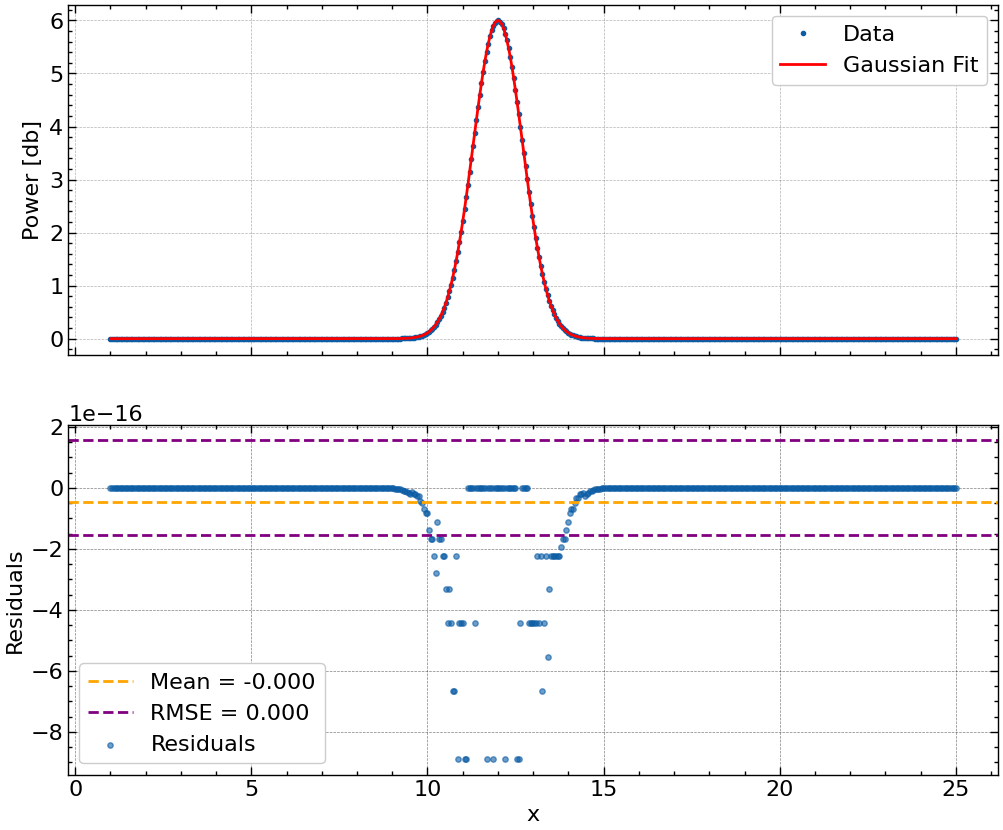

In [27]:
gaussian_fit_RFI(x, g1, tie=False)

The Chi-square is: 1.271
The Root Mean Squared Error: 5.486898791673899e-17
Number off corrupted channels: 70.0


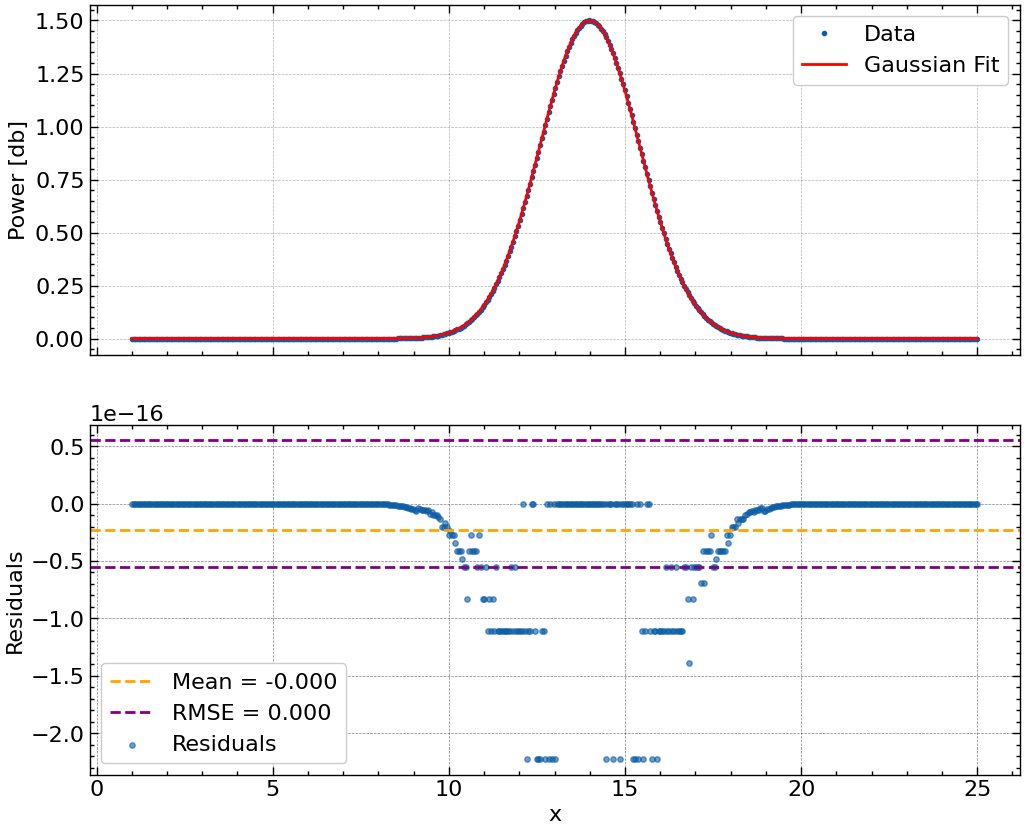

In [28]:
gaussian_fit_RFI(x, g2, tie=False)

The reduce_chi-square is: 1.1932657190655211
The Root Mean Squared Error: 0.4597532614588592
Number off corrupted channels: 88.0


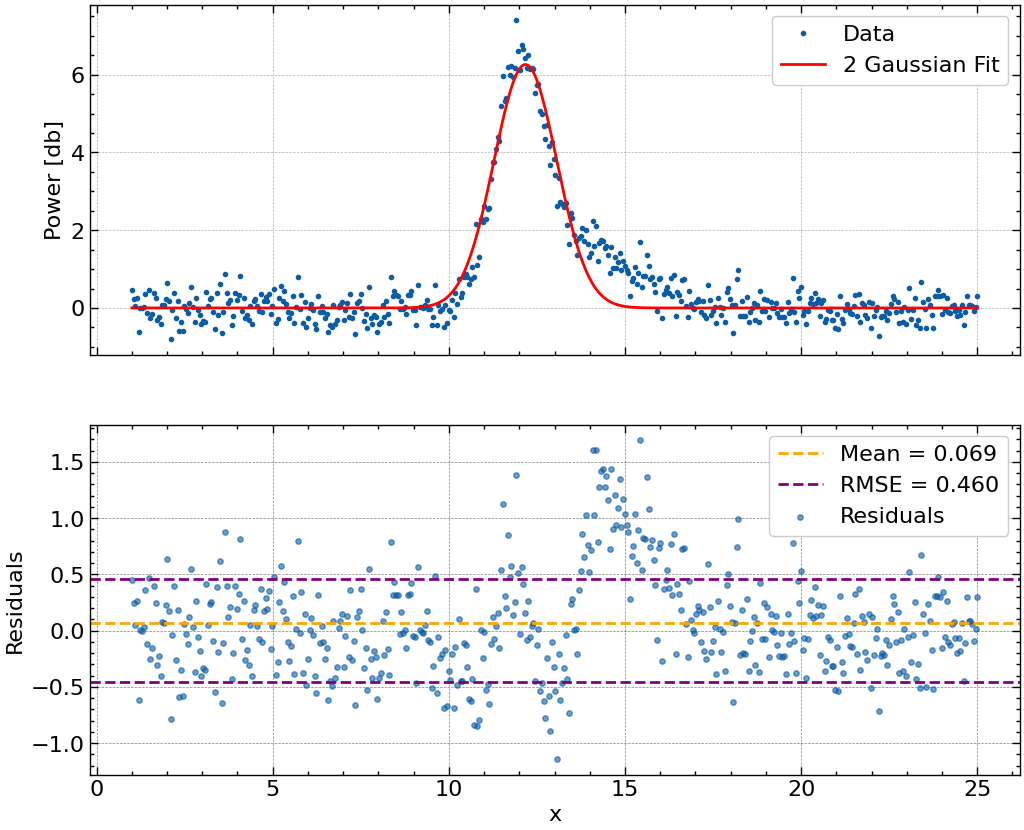

In [29]:
gaussian_fit_RFI(x, y_noisy, tie=True)

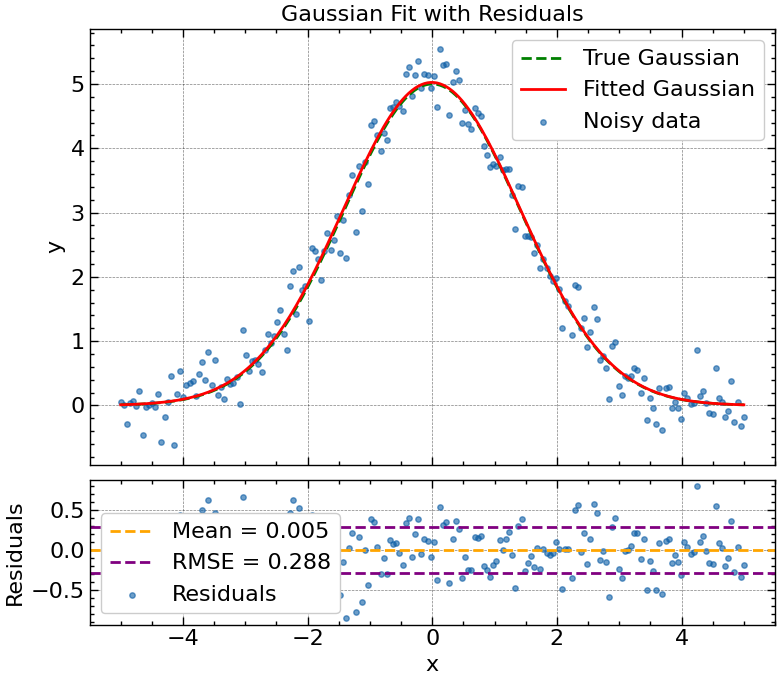

Mean residual = 0.0054
RMSE = 0.2882


In [ ]:


# --- Parameters for synthetic data
amp, mu, sigma = 5, 0, 1
x = np.linspace(-5, 5, 200)
y_true = gaussian_function(x, amp, mu, sigma)
y_noisy = y_true + np.random.normal(0, 0.3, x.shape)

# --- Fit with astropy
g_init = models.Gaussian1D(amplitude=4, mean=0.5, stddev=1.5)  # initial guess
fitter = fitting.LevMarLSQFitter()
g_fit = fitter(g_init, x, y_noisy)

# --- Residuals
residuals = y_noisy - g_fit(x)
res_mean = np.mean(residuals)
rmse = np.sqrt(np.mean(residuals**2))

# --- Plot with subplots
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 7), gridspec_kw={'height_ratios':[3,1]}, sharex=True)

# Main fit
ax1.scatter(x, y_noisy, s=15, alpha=0.6, label="Noisy data")
ax1.plot(x, y_true, "g--", lw=2, label="True Gaussian")
ax1.plot(x, g_fit(x), "r-", lw=2, label="Fitted Gaussian")
ax1.set_ylabel("y")
ax1.set_title("Gaussian Fit with Residuals")
ax1.legend()

# Residuals subplot
ax2.scatter(x, residuals, s=15, alpha=0.6, label="Residuals")
ax2.axhline(res_mean, color="orange", linestyle="--", lw=2, label=f"Mean = {res_mean:.3f}")
ax2.axhline(rmse, color="purple", linestyle="--", lw=2, label=f"RMSE = {rmse:.3f}")
ax2.axhline(-rmse, color="purple", linestyle="--", lw=2)  # symmetric RMSE band
ax2.set_xlabel("x")
ax2.set_ylabel("Residuals")
ax2.legend()

plt.tight_layout()
plt.show()

print(f"Mean residual = {res_mean:.4f}")
print(f"RMSE = {rmse:.4f}")


The Chi-square is: 5.010
The Root Mean Squared Error: 0.28819575477354986
Number off corrupted channels: 67.0


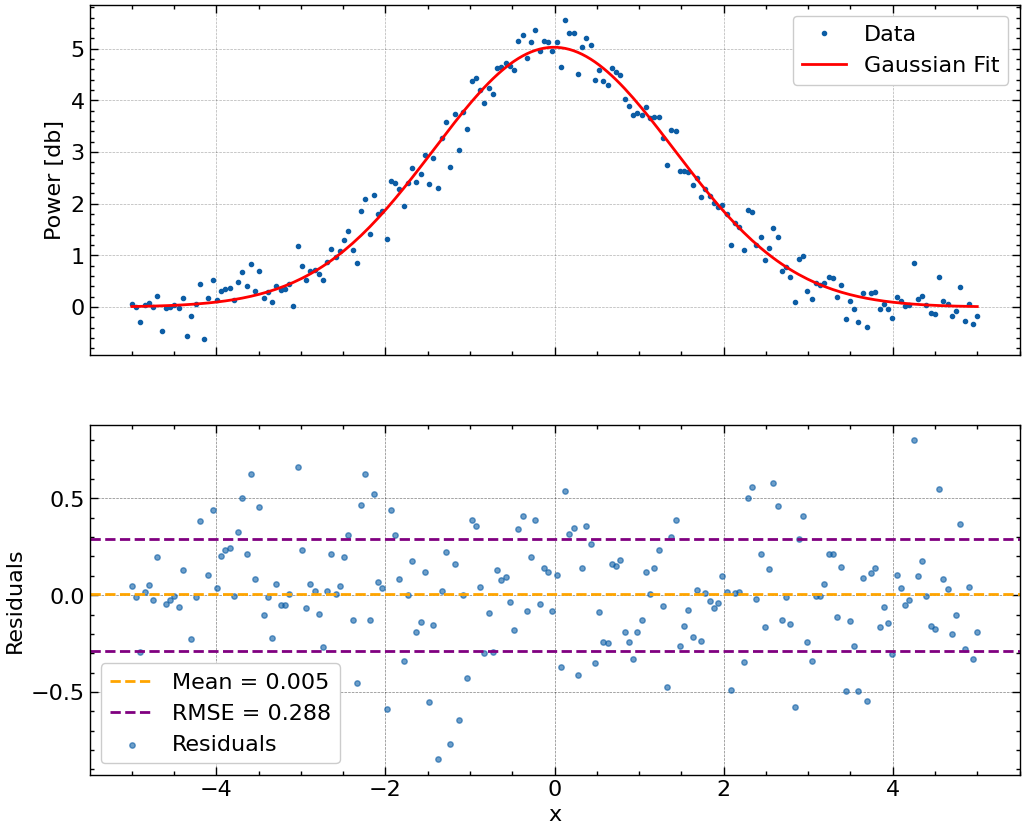

In [11]:
gaussian_fit_RFI(x, y_noisy, tie=False)